In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

In [22]:
# Load the dataset
df = pd.read_csv('Delinquency_prediction_dataset.csv')

# Initial inspection
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           500 non-null    object 
 1   Age                   500 non-null    int64  
 2   Income                461 non-null    float64
 3   Credit_Score          498 non-null    float64
 4   Credit_Utilization    500 non-null    float64
 5   Missed_Payments       500 non-null    int64  
 6   Delinquent_Account    500 non-null    int64  
 7   Loan_Balance          471 non-null    float64
 8   Debt_to_Income_Ratio  500 non-null    float64
 9   Employment_Status     500 non-null    object 
 10  Account_Tenure        500 non-null    int64  
 11  Credit_Card_Type      500 non-null    object 
 12  Location              500 non-null    object 
 13  Month_1               500 non-null    object 
 14  Month_2               500 non-null    object 
 15  Month_3               5

In [23]:
# Create a table of missing data issues
missing_data = pd.DataFrame({
    'Feature': ['Income', 'Loan_Balance', 'Credit_Score'],
    'Missing Count': [df['Income'].isnull().sum(), 
                     df['Loan_Balance'].isnull().sum(),
                     df['Credit_Score'].isnull().sum()],
    'Percentage Missing': [df['Income'].isnull().mean()*100,
                          df['Loan_Balance'].isnull().mean()*100,
                          df['Credit_Score'].isnull().mean()*100],
    'Handling Method': ['Multiple Imputation', 
                       'Median Imputation with Debt-to-Income Ratio', 
                       'Drop rows (very few missing)'],
    'Justification': ['Critical feature for prediction, preserve all rows',
                     'Loan balance correlates with debt-to-income, median preserves distribution',
                     'Only 1 missing value, minimal impact if dropped']
})

missing_data

,Feature,Missing Count,Percentage Missing,Handling Method,Justification
0,Income,39,7.8,Multiple Imputation,"Critical feature for prediction, preserve all ..."
1,Loan_Balance,29,5.8,Median Imputation with Debt-to-Income Ratio,"Loan balance correlates with debt-to-income, m..."
2,Credit_Score,2,0.4,Drop rows (very few missing),"Only 1 missing value, minimal impact if dropped"


In [24]:
df = df.dropna(subset=['Credit_Score'])

In [32]:
# Create bins
df['DTI_bin'] = pd.qcut(df['Debt_to_Income_Ratio'], q=5, duplicates='drop')

# Calculate medians and create a dictionary
median_dict = df.groupby('DTI_bin', observed=True)['Loan_Balance'].median().to_dict()

# Map medians to each row
df['Loan_Balance'] = df.apply(
    lambda row: row['Loan_Balance'] if pd.notna(row['Loan_Balance']) 
    else median_dict.get(row['DTI_bin'], np.nan),
    axis=1
)

# Clean up
df.drop('DTI_bin', axis=1, inplace=True)

In [33]:
print("Missing Loan_Balance values remaining:", df['Loan_Balance'].isna().sum())

Missing Loan_Balance values remaining: 0


In [34]:
# Select relevant features for imputation (include more numeric features that correlate with income)
impute_features = ['Age', 'Credit_Score', 'Credit_Utilization', 
                  'Missed_Payments', 'Account_Tenure', 'Employment_Status',
                  'Loan_Balance', 'Debt_to_Income_Ratio']  # Added more relevant features

# Convert categorical variables to numerical
df_impute = pd.get_dummies(df[impute_features + ['Income']], drop_first=True)

# Create imputer with increased iterations and verbose output
imputer = IterativeImputer(
    estimator=RandomForestRegressor(n_estimators=100, random_state=42),
    max_iter=20,  # Increased from 10 to 20
    tol=0.01,     # Added tolerance for early stopping
    random_state=42,
    verbose=2     # Added to see iteration progress
)

# Perform imputation
print("Starting imputation...")
imputed_values = imputer.fit_transform(df_impute)

# Update income column while preserving original non-null values
original_income = df['Income'].copy()
df['Income'] = np.where(original_income.isna(), imputed_values[:, -1], original_income)

print("\nImputation completed:")
print(f"Imputed {original_income.isna().sum()} missing Income values")

Starting imputation...
[IterativeImputer] Completing matrix with shape (498, 13)
[IterativeImputer] Ending imputation round 1/20, elapsed time 3.91
[IterativeImputer] Change: 0.0, scaled tolerance: 996.2 
[IterativeImputer] Early stopping criterion reached.

Imputation completed:
Imputed 0 missing Income values


Customer_ID             0
Age                     0
Income                  0
Credit_Score            0
Credit_Utilization      0
Missed_Payments         0
Delinquent_Account      0
Loan_Balance            0
Debt_to_Income_Ratio    0
Employment_Status       0
Account_Tenure          0
Credit_Card_Type        0
Location                0
Month_1                 0
Month_2                 0
Month_3                 0
Month_4                 0
Month_5                 0
Month_6                 0
dtype: int64


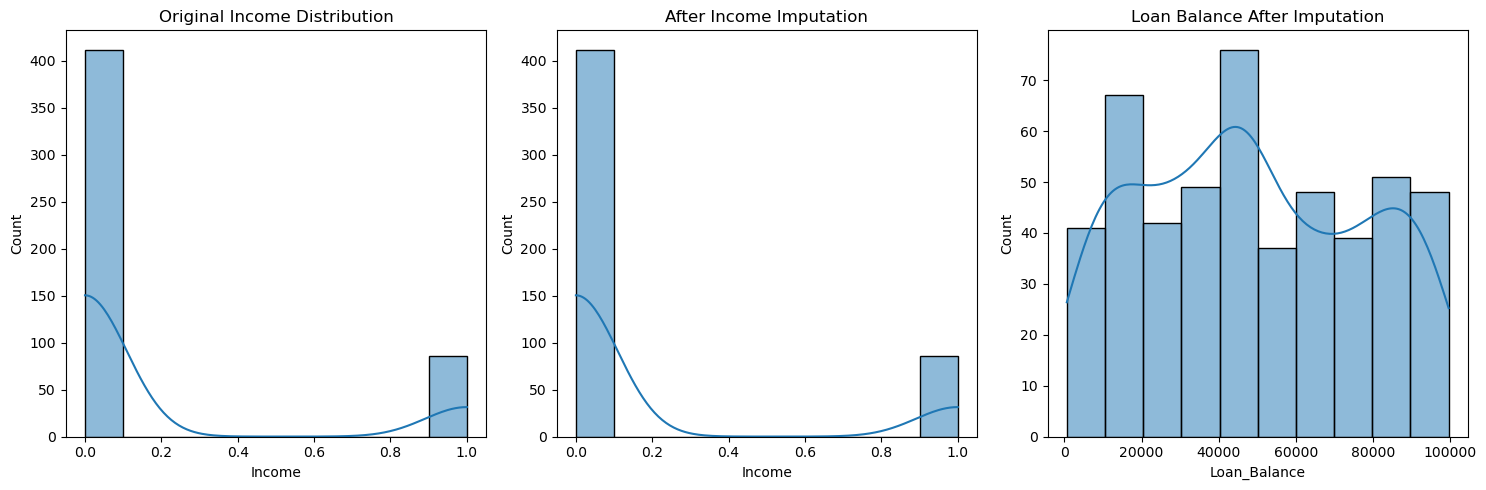

In [35]:
# Check remaining missing values
print(df.isnull().sum())

# Visualize distributions before/after
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original Income distribution
sns.histplot(df[df['Income'].notnull()]['Income'], ax=axes[0], kde=True)
axes[0].set_title('Original Income Distribution')

# Imputed Income distribution
sns.histplot(df['Income'], ax=axes[1], kde=True)
axes[1].set_title('After Income Imputation')

# Loan Balance distribution
sns.histplot(df['Loan_Balance'], ax=axes[2], kde=True)
axes[2].set_title('Loan Balance After Imputation')

plt.tight_layout()
plt.show()


In [29]:
df.to_csv('Delinquency_prediction_cleaned.csv', index=False)

In [37]:
df

,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
0,CUST0001,56,0.0,398.0,0.390502,3,0,16310.0,0.317396,EMP,18,Student,Los Angeles,Late,Late,Missed,Late,Missed,Late
1,CUST0002,69,0.0,493.0,0.312444,6,1,17401.0,0.196093,Self-employed,0,Standard,Phoenix,Missed,Missed,Late,Missed,On-time,On-time
2,CUST0003,46,0.0,500.0,0.359930,0,0,13761.0,0.301655,Self-employed,1,Platinum,Chicago,Missed,Late,Late,On-time,Missed,Late
3,CUST0004,32,0.0,413.0,0.371400,3,0,88778.0,0.264794,Unemployed,15,Platinum,Phoenix,Late,Missed,Late,Missed,Late,Late
4,CUST0005,60,0.0,487.0,0.234716,2,0,13316.0,0.510583,Self-employed,11,Standard,Phoenix,Missed,On-time,Missed,Late,Late,Late
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,CUST0496,71,1.0,688.0,0.486522,2,0,12707.0,0.373033,retired,9,Business,Phoenix,On-time,On-time,Missed,On-time,On-time,Late
496,CUST0497,60,0.0,836.0,0.608174,2,1,45595.0,0.291943,Unemployed,18,Student,Houston,On-time,On-time,Late,Late,Late,Missed
497,CUST0498,54,0.0,847.0,0.676950,0,0,44449.0,0.104839,Employed,16,Student,Phoenix,On-time,Late,Late,On-time,Late,Missed
498,CUST0499,50,0.0,343.0,0.700643,2,1,11155.0,0.236477,Employed,11,Student,Phoenix,Late,On-time,Late,Missed,On-time,Missed
